# Análise de Modelos e Métricas — Predição de Carga Alta (EVCOMX)

Segue a **Aula 06 do bootcamp** (slides citados como "slide N") e continua a pasta
`selecao_algoritmos/`. A seleção escolheu o modelo; aqui medimos **o que ele entrega**, com
as métricas certas, e traduzimos os erros para a língua da operação.

O roteiro é o "passo a passo para avaliar um modelo" do slide 37:

| Passo da aula (slide 37) | Seção |
|---|---|
| 1. Descubra qual erro custa mais caro | 1 |
| 2. Escolha a métrica principal antes de testar | 2 |
| 3. Calcule o baseline com a mesma métrica | 3 |
| 4. Compare modelos com validação cruzada | 4 e 5 |
| 5. Olhe a matriz de confusão do melhor | 6 |
| 6. Ajuste o ponto de corte ao negócio | 7 |
| Extra: a "chance" do modelo é chance de verdade? | 8 |
| Extra: o desempenho se mantém no tempo? | 9 |
| 7. Confira no teste e traduza em custo | 10 e 11 |
| Extra: o modelo para uso (treino + validação) no teste | 11 |
| Métricas de regressão (slides 24 a 29) | 12 |

**Rode antes** `EDA/transforma_dataset.py`, `feature_selection/feature_selection.py` e
`selecao_algoritmos/selecao_algoritmos.py`. Nada aqui escolhe algoritmo, features ou limiar
de novo: tudo isso veio da seleção. Esta etapa só mede, compara e traduz.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, brier_score_loss, confusion_matrix,
                             classification_report, roc_curve, precision_recall_curve)

SEED = 42
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e5e5e5", "grid.linewidth": 0.6, "axes.axisbelow": True})
# mesma paleta da EDA, da feature selection e da seleção de algoritmos
AZUL, VERMELHO, CINZA, LARANJA, VERDE = "#2b6cb0", "#c0392b", "#7f8c8d", "#dd8a2e", "#4a8c4a"

## 0. Ler os arquivos das etapas anteriores

- `feature_selection/dataset_features_completo.csv`: features, `conjunto` (split 70/15/15
  temporal) e `carga_alta`.
- `selecao_algoritmos/modelo_final.json`: algoritmo, features, hiperparâmetros e os três
  limiares de cada plano (escolhidos na validação).
- `selecao_algoritmos/previsoes_validacao_teste.csv`: a chance prevista por cestão.
- `original_dataset/VariavelResposta.csv`: a **duração da parada** de cada carga alta. Não é
  feature (só existe depois do evento); serve aqui para traduzir erros em minutos.

Os modelos `.joblib` da seleção foram re-treinados em treino + validação, então não podem ser
avaliados na validação. Por isso **re-treinamos aqui, só no treino**, os mesmos algoritmos com
os mesmos hiperparâmetros, e conferimos que as chances batem com as da seleção.

In [2]:
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "selecao_algoritmos").is_dir() and (p / "original_dataset").is_dir())
PASTA_FS = RAIZ / "feature_selection"
PASTA_SEL = RAIZ / "selecao_algoritmos"
PASTA_SAIDA = RAIZ / "analise_modelos"
PASTA_GRAF = PASTA_SAIDA / "graficos"
PASTA_GRAF.mkdir(parents=True, exist_ok=True)

def br(x, casas=2):
    """Número no formato brasileiro, para títulos e legendas: 0.425 -> '0,42'."""
    return f"{x:.{casas}f}".replace(".", ",")

def salvar(nome):
    plt.tight_layout()
    plt.savefig(PASTA_GRAF / f"{nome}.png", dpi=130, bbox_inches="tight")
    plt.show()

for arq in ["modelo_final.json", "previsoes_validacao_teste.csv"]:
    assert (PASTA_SEL / arq).exists(), f"selecao_algoritmos/{arq} não existe: rode o selecao_algoritmos.py primeiro!"

info = json.loads((PASTA_SEL / "modelo_final.json").read_text(encoding="utf-8"))
COLS_A, COLS_B = info["plano_A"]["features"], info["plano_B"]["features"]
LIM_A, LIM_B = info["plano_A"]["limiares"], info["plano_B"]["limiares"]
CENARIOS = list(LIM_A)  # ["não deixar passar (F2)", "equilíbrio (F1)", "evitar alarme falso (F0,5)"]
CURTO = {c: c.split(" (")[0] for c in CENARIOS}

df = pd.read_csv(PASTA_FS / "dataset_features_completo.csv")
df["inicio"] = pd.to_datetime(df["inicio"], utc=True, format="ISO8601")
df = df.sort_values(["inicio", "cd_corrida", "nu_carregamento"]).reset_index(drop=True)

# duração da parada por cestão (segundos; zero quando não houve carga alta)
resp = pd.read_csv(RAIZ / "original_dataset" / "VariavelResposta.csv")
dur = pd.concat([
    resp[["cd_corrida", f"qt_segundos_duracao_parada_carregamento_{n}"]]
        .set_axis(["cd_corrida", "seg_parada"], axis=1).assign(nu_carregamento=float(n))
    for n in (1, 2)])
df = df.merge(dur, on=["cd_corrida", "nu_carregamento"], how="left", validate="one_to_one")
assert df["seg_parada"].notna().all()
assert ((df["seg_parada"] > 0) == (df["carga_alta"] == 1)).all(), "duração > 0 deveria existir só com carga alta"

treino = df[df.conjunto == "treino"].reset_index(drop=True)
valid = df[df.conjunto == "validacao"].reset_index(drop=True)
teste = df[df.conjunto == "teste"].reset_index(drop=True)
y_tr, y_va, y_te = treino["carga_alta"], valid["carga_alta"], teste["carga_alta"]

def periodo(d):
    a, b = d["inicio"].min().tz_convert("America/Sao_Paulo"), d["inicio"].max().tz_convert("America/Sao_Paulo")
    return f"{a:%d/%m/%Y}–{b:%d/%m/%Y}"
pd.DataFrame({"cestões": [len(treino), len(valid), len(teste)],
              "cargas altas": [y_tr.sum(), y_va.sum(), y_te.sum()],
              "taxa": [y_tr.mean(), y_va.mean(), y_te.mean()],
              "período": [periodo(treino), periodo(valid), periodo(teste)]},
             index=["treino", "validação", "teste"]).round(3)

,cestões,cargas altas,taxa,período
treino,2473,392,0.159,14/08/2025–25/04/2026
validação,513,92,0.179,25/04/2026–27/06/2026
teste,515,75,0.146,24/06/2026–04/08/2026


### Os modelos, re-treinados só no treino

Mesmas definições "de fábrica" da seleção (seção 5 de `selecao_algoritmos.py`). A Random Forest
com as 9 features é o **plano A**; com as 7 sem histórico, o **plano B**.

In [3]:
def montar(modelo, escala=False):
    passos = [("vazios", SimpleImputer(strategy="median"))]
    if escala:
        passos.append(("escala", StandardScaler()))
    passos.append(("modelo", modelo))
    return Pipeline(passos)

ALGOS = {
    "Regressão logística": montar(LogisticRegression(max_iter=2000, class_weight="balanced"), escala=True),
    "Árvore de decisão": montar(DecisionTreeClassifier(max_depth=4, min_samples_leaf=20,
                                                       class_weight="balanced", random_state=SEED)),
    "Random Forest": montar(RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                                   class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)),
    "Gradient Boosting": montar(GradientBoostingClassifier(learning_rate=0.05, n_estimators=200, max_depth=3,
                                                           subsample=0.8, random_state=SEED)),
}
COR = {"Regressão logística": LARANJA, "Árvore de decisão": VERDE, "Random Forest": AZUL,
       "Gradient Boosting": VERMELHO}
ESTILO = {"Regressão logística": ":", "Árvore de decisão": "-.", "Random Forest": "-", "Gradient Boosting": "--"}

hp = info["plano_A"]["hiperparametros"]
assert info["plano_A"]["algoritmo"] == "Random Forest" and hp["n_estimators"] == 300 and hp["min_samples_leaf"] == 5, \
    "O modelo escolhido na seleção mudou: atualize ALGOS antes de seguir."

modelos = {nome: clone(m).fit(treino[COLS_A], y_tr) for nome, m in ALGOS.items()}
modelo_B = clone(ALGOS["Random Forest"]).fit(treino[COLS_B], y_tr)

p_va = {nome: m.predict_proba(valid[COLS_A])[:, 1] for nome, m in modelos.items()}
p_te = {nome: m.predict_proba(teste[COLS_A])[:, 1] for nome, m in modelos.items()}
p_va_A, p_te_A = p_va["Random Forest"], p_te["Random Forest"]
p_va_B, p_te_B = modelo_B.predict_proba(valid[COLS_B])[:, 1], modelo_B.predict_proba(teste[COLS_B])[:, 1]

# conferência: as chances re-treinadas aqui são as mesmas da seleção
prev_sel = pd.read_csv(PASTA_SEL / "previsoes_validacao_teste.csv")
for nome_conj, base, pa, pb in [("validacao", valid, p_va_A, p_va_B), ("teste", teste, p_te_A, p_te_B)]:
    s = base[["cd_corrida", "nu_carregamento"]].assign(pa=pa, pb=pb).merge(
        prev_sel[prev_sel.conjunto == nome_conj], on=["cd_corrida", "nu_carregamento"], validate="one_to_one")
    assert len(s) == len(base)
    assert np.allclose(s["pa"], s["prob_planoA"], atol=1e-9) and np.allclose(s["pb"], s["prob_planoB"], atol=1e-9), \
        f"As chances não batem com a seleção em {nome_conj}: confira versão do scikit-learn ou os CSVs."
print("Conferência OK: chances idênticas às de selecao_algoritmos/previsoes_validacao_teste.csv")

Conferência OK: chances idênticas às de selecao_algoritmos/previsoes_validacao_teste.csv


## 1. Qual erro custa mais caro? (slides 5, 7 e 9; passo 1)

Os quatro resultados do "alarme de incêndio" (slide 7), traduzidos para o pátio:

| | O cestão deu carga alta | O cestão foi normal |
|---|---|---|
| **Modelo deu alarme** | **VP**: alarme certo. Dá para mexer no cestão antes de despejar. | **FP — alarme falso**: o pátio mexe num cestão que estava bom. |
| **Modelo não deu alarme** | **FN — deixou passar**: forno parado, eletrodos sem arco, energia desperdiçada (Guia EDA). | **VN**: tudo normal. |

**O custo de um FN nós conseguimos medir**: é a duração da parada, que está nos dados.
**O custo de um FP, não**: depende do que o pátio faz com o alarme (rearranjar o cestão,
trocar material, só observar). Perguntamos à EVCOMX em 18/10/2026 (pergunta 3 do e-mail).

Enquanto a resposta não chega, trabalhamos com a **razão de custo**
`k = custo de 1 carga alta não detectada ÷ custo de 1 alarme falso`. Se os dois custos forem
medidos em minutos, `k = minutos de parada de uma carga alta ÷ minutos perdidos com um alarme falso`.

Uma ressalva honesta: tratar o FN como "parada evitável" supõe que o alarme permite **evitar**
a carga alta. Se o pátio não conseguir agir a tempo, o ganho real é menor.

In [4]:
minutos = df.loc[df.carga_alta == 1].assign(min_parada=lambda d: d["seg_parada"] / 60)
dias = {c: (d["inicio"].max() - d["inicio"].min()).total_seconds() / 86400 for c, d in df.groupby("conjunto")}
tab_parada = minutos.groupby("conjunto")["min_parada"].agg(
    cargas_altas="size", media_min="mean", mediana_min="median", p90_min=lambda s: s.quantile(0.9),
    total_min="sum").loc[["treino", "validacao", "teste"]]
tab_parada["total_min_por_30_dias"] = tab_parada["total_min"] / pd.Series(dias) * 30
MIN_FN = minutos.loc[minutos.conjunto == "treino", "min_parada"].mean()   # custo médio de um FN, medido no treino
print(f"Uma carga alta para o forno, em média, {MIN_FN:.1f} min (treino). "
      f"Mediana {tab_parada.loc['treino', 'mediana_min']:.1f} min: poucas paradas longas puxam a média.")
tab_parada.round(1)

Uma carga alta para o forno, em média, 4.0 min (treino). Mediana 3.0 min: poucas paradas longas puxam a média.


,cargas_altas,media_min,mediana_min,p90_min,total_min,total_min_por_30_dias
conjunto,,,,,,
treino,392,4.0,3.0,8.3,1580.7,186.6
validacao,92,4.0,3.0,7.4,364.2,174.0
teste,75,3.3,2.1,9.6,251.1,184.8


## 2. A métrica principal, escolhida antes de testar (slides 18, 35 e 36; passo 2)

A métrica foi definida na seleção **antes** de comparar modelos (slide 36: "escolher a métrica
depois" é erro comum). Revendo pelas perguntas do slide 35:

| Pergunta (slide 35) | Resposta neste projeto | Consequência |
|---|---|---|
| Número ou categoria? | Categoria: carga alta sim/não | Classificação; MAE/RMSE não se aplicam (seção 12) |
| Classes de tamanho parecido? | Não: ~15–18% de carga alta | **Esquecer a acurácia sozinha** |
| Qual erro custa mais caro? | FN mede-se em minutos; FP, à espera da EVCOMX | Recall e precisão entram **depois**, com o limiar |
| Vou escolher o corte depois? | Sim (seção 7) | Comparar modelos com uma métrica **sem corte** |
| Quem vai ler? | Pátio e gestão da EVCOMX | Traduzir em alarmes e minutos a cada 100 cestões |

**Por que PR-AUC e não só ROC-AUC (slide 22)?** As duas avaliam todos os cortes. A ROC-AUC
usa a taxa de alarmes falsos entre os **normais**, que são ~83% dos cestões: mesmo muitos
alarmes falsos viram uma taxa pequena, e a curva fica bonita. A PR-AUC usa a **precisão**
("quando o alarme toca, é carga alta?"), que é o que o pátio sente. O chute tem ROC-AUC 0,5
sempre, mas PR-AUC igual à taxa de carga alta (~0,15–0,18). Reportamos as duas.

Como na seleção, a "PR-AUC" é calculada com `average_precision_score` (a precisão média ao longo
da curva), que é a forma recomendada pelo scikit-learn de resumir a curva precisão-recall.

**A armadilha da acurácia (slide 13), com os nossos dados:**

In [5]:
def metricas_no_corte(y, p, lim):
    prev = (p >= lim).astype(int)
    return {"acurácia": accuracy_score(y, prev), "precisão": precision_score(y, prev, zero_division=0),
            "recall": recall_score(y, prev), "F1": f1_score(y, prev, zero_division=0),
            "alarmes/100": 100 * prev.mean()}

armadilha = pd.DataFrame({
    "sempre 'normal' (preguiçoso)": metricas_no_corte(y_va, np.zeros(len(y_va)), 0.5),
    "Random Forest, corte padrão 0,5": metricas_no_corte(y_va, p_va_A, 0.5),
    f"Random Forest, corte '{CURTO[CENARIOS[0]]}'": metricas_no_corte(y_va, p_va_A, LIM_A[CENARIOS[0]]),
}).T
print("Na validação: o modelo preguiçoso tem a MAIOR acurácia e não encontra nenhuma carga alta.")
armadilha.round(3)

Na validação: o modelo preguiçoso tem a MAIOR acurácia e não encontra nenhuma carga alta.


,acurácia,precisão,recall,F1,alarmes/100
sempre 'normal' (preguiçoso),0.821,0.000,0.000,0.000,0.000
"Random Forest, corte padrão 0,5",0.737,0.352,0.554,0.430,28.265
"Random Forest, corte 'não deixar passar'",0.596,0.271,0.739,0.397,48.928


## 3. Baselines, na mesma métrica (slides 3 e 36; passo 3)

Além dos dois "modelos de mentira" da Aula 05 (maioria e sorteio), testamos **baselines de uma
regra só**: ordenar os cestões por **uma** feature, sem treinar nada. São a régua honesta para
a pergunta "precisava de um modelo?".

- `taxa_ca_ult5`: "o forno está ruim" (carga alta recente). Se o modelo mal superar essa regra,
  a composição do cestão quase não ajuda.
- `densidade_media` e `prop_peso_pesado`: "o cestão está fofo".

O sentido de cada regra (mais = mais risco, ou menos = mais risco) vem do **treino**.

In [6]:
def recall_no_orcamento(y, p, frac=0.20):
    """Recall quando o pátio só pode olhar os `frac` cestões de maior risco. Compara modelos sem
    depender do corte de cada um: todos disparam o mesmo número de alarmes.
    Empates na fronteira (comuns nas regras, como taxa_ca_ult5 = 0,2) são divididos na proporção,
    como num sorteio: o resultado não depende da ordem das linhas."""
    y, p = np.asarray(y), np.asarray(p)
    n = int(round(frac * len(p)))
    corte = np.sort(p)[::-1][n - 1]
    acima, empate = p > corte, p == corte
    vagas = n - acima.sum()
    achados = y[acima].sum() + vagas * y[empate].mean()
    return achados / y.sum()

REGRAS = ["taxa_ca_ult5", "densidade_media", "prop_peso_pesado"]
mediana_tr = treino[REGRAS].median()
SINAL = {f: np.sign(treino[[f, "carga_alta"]].corr(method="spearman").iloc[0, 1]) for f in REGRAS}
def regra(base, f):
    return SINAL[f] * base[f].fillna(mediana_tr[f]).to_numpy()
linhas = []
dummy = {"Baseline: maioria": DummyClassifier(strategy="most_frequent"),
         "Baseline: sorteio": DummyClassifier(strategy="stratified", random_state=SEED)}
for nome, d in dummy.items():
    p = d.fit(treino[COLS_A], y_tr).predict_proba(valid[COLS_A])[:, 1]
    linhas.append({"modelo": nome, "PR-AUC": average_precision_score(y_va, p), "ROC-AUC": roc_auc_score(y_va, p),
                   "recall c/ 20 alarmes por 100": recall_no_orcamento(y_va, p)})
for f in REGRAS:
    p = regra(valid, f)
    linhas.append({"modelo": f"Regra: {'mais' if SINAL[f] > 0 else 'menos'} {f}", "PR-AUC": average_precision_score(y_va, p),
                   "ROC-AUC": roc_auc_score(y_va, p), "recall c/ 20 alarmes por 100": recall_no_orcamento(y_va, p)})
linhas.append({"modelo": "Random Forest (plano A)", "PR-AUC": average_precision_score(y_va, p_va_A),
               "ROC-AUC": roc_auc_score(y_va, p_va_A), "recall c/ 20 alarmes por 100": recall_no_orcamento(y_va, p_va_A)})
tab_baseline = pd.DataFrame(linhas).set_index("modelo")
print("Validação (abr–jun/2026). Recall com 20 alarmes por 100: das cargas altas, quantas estão entre os 20% de maior risco.")
print("A regra 'carga alta recente' sozinha chega perto do modelo; as regras de composição sozinhas ficam no nível do chute.\n")
tab_baseline.round(3)

Validação (abr–jun/2026). Recall com 20 alarmes por 100: das cargas altas, quantas estão entre os 20% de maior risco.
A regra 'carga alta recente' sozinha chega perto do modelo; as regras de composição sozinhas ficam no nível do chute.



,PR-AUC,ROC-AUC,recall c/ 20 alarmes por 100
modelo,,,
Baseline: maioria,0.179,0.500,0.201
Baseline: sorteio,0.187,0.521,0.235
Regra: mais taxa_ca_ult5,0.337,0.691,0.418
Regra: menos densidade_media,0.169,0.486,0.141
Regra: menos prop_peso_pesado,0.207,0.573,0.239
Random Forest (plano A),0.425,0.716,0.446


**Leitura.** No regime pós-maio, as features de composição **sozinhas** quase não separam os
cestões (a densidade sozinha fica no nível do chute). Boa parte do poder do modelo vem do
histórico do forno. Se o modelo supera a regra do histórico de verdade é medido na seção 4
(validação) e na seção 11 (teste). Isso reforça a pergunta não feita à EVCOMX: **o resultado
da corrida anterior está disponível na hora de prever?**

## 4. Comparação justa com validação cruzada temporal, várias métricas (slides 31 e 32; passo 4)

Como no slide 32, mas com as provas **temporais** da seleção (janela crescente dentro do treino,
por corrida). O `cv=5` da aula divide o treino em 5 partes e, em 4 das 5 provas, treina com
meses **posteriores** para prever meses anteriores: o modelo "veria o futuro", o que não
acontece na operação. Além disso, `taxa_ca_ult5/10` olham para as corridas anteriores.

Calculamos as métricas de duas formas:
- **no corte padrão 0,5** (o que `cross_validate` faz). Atenção: aqui o corte **não é justo**
  entre algoritmos. Logística, árvore e Random Forest usam `class_weight="balanced"`, que empurra
  as chances para cima; o Gradient Boosting não tem esse parâmetro e quase nunca passa de 0,5.
  O recall baixo dele é efeito do corte, não do algoritmo (slide 16);
- **com o mesmo orçamento de alarmes** (20 a cada 100 cestões, o de maior risco). Assim todo
  modelo dispara o mesmo número de alarmes e a comparação fica justa.

In [7]:
def dobras_temporais(dados, n_blocos=6):   # idêntica à da seleção
    ordem = dados.groupby("cd_corrida")["inicio"].min().sort_values()
    bloco_corrida = pd.Series(np.arange(len(ordem)) * n_blocos // len(ordem), index=ordem.index)
    bloco = dados["cd_corrida"].map(bloco_corrida).to_numpy()
    return [(np.where(bloco <= k)[0], np.where(bloco == k + 1)[0]) for k in range(n_blocos - 1)]

CV = dobras_temporais(treino)

def todas_metricas(y, p):
    m = metricas_no_corte(y, p, 0.5)
    return {"acurácia (0,5)": m["acurácia"], "precisão (0,5)": m["precisão"], "recall (0,5)": m["recall"],
            "F1 (0,5)": m["F1"], "ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p),
            "recall c/ 20 alarmes por 100": recall_no_orcamento(y, p)}

reg_cv, P_CV = [], {}   # P_CV guarda as chances de cada prova (reusadas na seção 9)
for nome, m in ALGOS.items():
    for i, (a, b) in enumerate(CV, 1):
        p = clone(m).fit(treino.loc[a, COLS_A], y_tr[a]).predict_proba(treino.loc[b, COLS_A])[:, 1]
        P_CV[(nome, i)] = p
        reg_cv.append({"algoritmo": nome, "prova": i, **todas_metricas(y_tr[b].to_numpy(), p)})
reg_cv = pd.DataFrame(reg_cv)
METRICAS = [c for c in reg_cv.columns if c not in ("algoritmo", "prova")]
tab_cv = reg_cv.groupby("algoritmo")[METRICAS].agg(["mean", "std"]).loc[list(ALGOS)]
tab_cv_txt = pd.DataFrame({m: [f"{tab_cv.loc[a, (m, 'mean')]:.2f} ± {tab_cv.loc[a, (m, 'std')]:.2f}" for a in ALGOS]
                           for m in METRICAS}, index=list(ALGOS))
print("Validação cruzada temporal no treino (ago/2025–abr/2026): média ± desvio nas 5 provas")
tab_cv_txt

Validação cruzada temporal no treino (ago/2025–abr/2026): média ± desvio nas 5 provas


,"acurácia (0,5)","precisão (0,5)","recall (0,5)","F1 (0,5)",ROC-AUC,PR-AUC,recall c/ 20 alarmes por 100
Regressão logística,0.76 ± 0.09,0.35 ± 0.09,0.66 ± 0.11,0.46 ± 0.09,0.78 ± 0.09,0.44 ± 0.17,0.52 ± 0.17
Árvore de decisão,0.68 ± 0.09,0.28 ± 0.09,0.62 ± 0.11,0.37 ± 0.09,0.74 ± 0.07,0.37 ± 0.11,0.46 ± 0.13
Random Forest,0.82 ± 0.06,0.41 ± 0.14,0.38 ± 0.14,0.39 ± 0.14,0.75 ± 0.08,0.40 ± 0.12,0.46 ± 0.14
Gradient Boosting,0.84 ± 0.05,0.43 ± 0.18,0.17 ± 0.07,0.24 ± 0.08,0.74 ± 0.07,0.36 ± 0.09,0.46 ± 0.11


### As mesmas métricas na validação (abr–jun/2026), com intervalo de confiança

A validação é o período mais recente antes do teste, e já está no regime pós-maio/2026. Foi
ela que decidiu o modelo na seleção. O intervalo de 90% vem de um *bootstrap* por corrida
(os dois cestões de uma corrida são sorteados juntos).

In [8]:
rng = np.random.default_rng(SEED)
def amostras_bootstrap(base, n=1000):
    idx = base.groupby("cd_corrida").indices
    corr = np.array(list(idx))
    return [np.concatenate([idx[c] for c in rng.choice(corr, len(corr))]) for _ in range(n)]

BOOT_VA = amostras_bootstrap(valid)
def ic90(y, p, func, amostras):
    y = np.asarray(y)
    v = [func(y[a], p[a]) for a in amostras]
    return np.percentile(v, 5), np.percentile(v, 95)

linhas = []
for nome in ALGOS:
    m = todas_metricas(y_va.to_numpy(), p_va[nome])
    lo, hi = ic90(y_va, p_va[nome], average_precision_score, BOOT_VA)
    lo_r, hi_r = ic90(y_va, p_va[nome], recall_no_orcamento, BOOT_VA)
    linhas.append({"algoritmo": nome, **m, "PR-AUC IC90": f"{lo:.2f}–{hi:.2f}",
                   "recall 20/100 IC90": f"{lo_r:.2f}–{hi_r:.2f}"})
tab_val = pd.DataFrame(linhas).set_index("algoritmo")
tab_val.round(3)

,"acurácia (0,5)","precisão (0,5)","recall (0,5)","F1 (0,5)",ROC-AUC,PR-AUC,recall c/ 20 alarmes por 100,PR-AUC IC90,recall 20/100 IC90
algoritmo,,,,,,,,,
Regressão logística,0.499,0.238,0.815,0.369,0.651,0.257,0.337,0.21–0.32,0.26–0.41
Árvore de decisão,0.501,0.239,0.815,0.369,0.690,0.313,0.381,0.25–0.38,0.32–0.44
Random Forest,0.737,0.352,0.554,0.430,0.716,0.425,0.446,0.34–0.52,0.37–0.52
Gradient Boosting,0.813,0.462,0.261,0.333,0.712,0.386,0.435,0.31–0.48,0.36–0.52


### A diferença entre os modelos é real ou sorte? (slide 36: "ignorar a variação")

*Bootstrap* pareado: em cada sorteio da validação, medimos a PR-AUC da Random Forest **e** do
concorrente nos **mesmos** cestões. Se a Random Forest vence em quase todos os sorteios, a
diferença é real; perto de 50%, é empate.

In [9]:
yv = y_va.to_numpy()
P_REGRA_VA = regra(valid, "taxa_ca_ult5")
concorrentes = {nome: p_va[nome] for nome in ALGOS if nome != "Random Forest"}
concorrentes["Regra: mais taxa_ca_ult5 (só histórico)"] = P_REGRA_VA
linhas = []
for nome, pc in concorrentes.items():
    for met, func in [("PR-AUC", average_precision_score), ("recall 20/100", recall_no_orcamento)]:
        dif = np.array([func(yv[a], p_va_A[a]) - func(yv[a], pc[a]) for a in BOOT_VA])
        linhas.append({"Random Forest contra": nome, "métrica": met, "diferença": func(yv, p_va_A) - func(yv, pc),
                       "IC90 da diferença": f"{np.percentile(dif, 5):+.2f} a {np.percentile(dif, 95):+.2f}",
                       "% dos sorteios em que a RF vence": 100 * (dif > 0).mean()})
tab_pareada = pd.DataFrame(linhas).set_index(["Random Forest contra", "métrica"])

def veredito(pct):
    if pct >= 95: return "vantagem real"
    if pct >= 80: return "vantagem provável"
    if pct <= 5: return "desvantagem real"
    if pct <= 20: return "desvantagem provável"
    return "empate"
tab_pareada["leitura"] = tab_pareada["% dos sorteios em que a RF vence"].map(veredito)
print("Critério: RF vence em ≥ 95% dos sorteios = vantagem real; 80–95% = provável; 20–80% = empate; "
      "abaixo de 20% e de 5%, desvantagem provável e real.")
print("O slide 31 manda, no empate, preferir o mais estável e mais simples: foi o que a seleção fez com o Gradient Boosting.\n")
tab_pareada.round(3)

Critério: RF vence em ≥ 95% dos sorteios = vantagem real; 80–95% = provável; 20–80% = empate; abaixo de 20% e de 5%, desvantagem provável e real.
O slide 31 manda, no empate, preferir o mais estável e mais simples: foi o que a seleção fez com o Gradient Boosting.



diferença IC90 da diferença  % dos sorteios em que a RF vence            leitura
Random Forest contra                    métrica                                                                                        
Regressão logística                     PR-AUC             0.168     +0.10 a +0.23                             100.0      vantagem real
                                        recall 20/100      0.109     +0.05 a +0.18                              99.6      vantagem real
Árvore de decisão                       PR-AUC             0.112     +0.06 a +0.17                             100.0      vantagem real
                                        recall 20/100      0.064     +0.01 a +0.12                              98.4      vantagem real
Gradient Boosting                       PR-AUC             0.038     -0.01 a +0.08                              91.5  vantagem provável
                                        recall 20/100      0.011     -0.05 a +0.06                              46.4             empate
Regra: mais taxa_ca_ult5 (só histórico) PR-AUC             0.088     +0.01 a +0.17                              97.2      vantagem real
                                        recall 20/100      0.028     -0.05 a +0.11                              73.7             empate

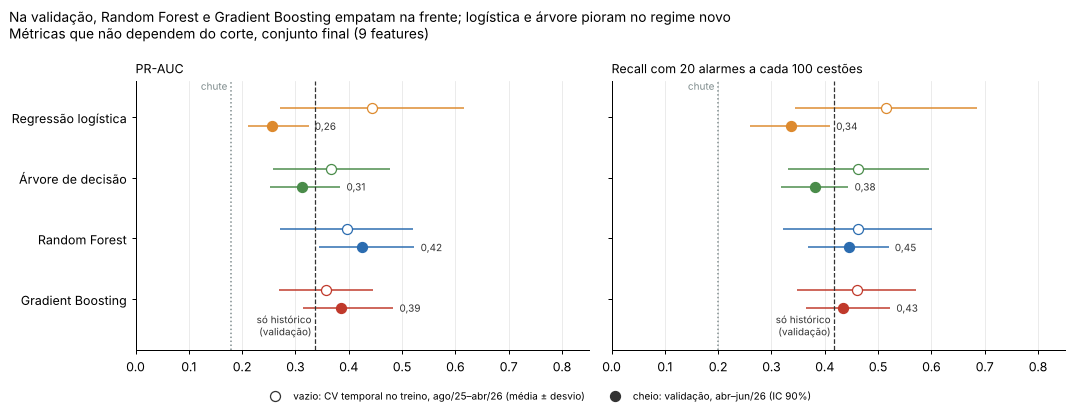

In [10]:
# Gráfico 01: CV x validação, nas duas métricas sem corte (PR-AUC e recall com orçamento fixo)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True)
ypos = np.arange(len(ALGOS))[::-1]
for ax, met, titulo, chute in [
        (axes[0], "PR-AUC", "PR-AUC", (y_tr.mean(), y_va.mean())),
        (axes[1], "recall c/ 20 alarmes por 100", "Recall com 20 alarmes a cada 100 cestões", (0.20, 0.20))]:
    for y0, nome in zip(ypos, ALGOS):
        mu, dp = tab_cv.loc[nome, (met, "mean")], tab_cv.loc[nome, (met, "std")]
        ax.errorbar(mu, y0 + 0.15, xerr=dp, fmt="o", mfc="white", mec=COR[nome], ecolor=COR[nome],
                    ms=8, elinewidth=1.2, capsize=0)
        if met == "PR-AUC":
            lo, hi = ic90(y_va, p_va[nome], average_precision_score, BOOT_VA)
        else:
            lo, hi = ic90(y_va, p_va[nome], recall_no_orcamento, BOOT_VA)
        v = tab_val.loc[nome, met]
        ax.errorbar(v, y0 - 0.15, xerr=[[v - lo], [hi - v]], fmt="o", color=COR[nome], ms=8, elinewidth=1.2, capsize=0)
        ax.annotate(f"{v:.2f}".replace(".", ","), (hi, y0 - 0.15), xytext=(5, -3), textcoords="offset points",
                    fontsize=8, color="#333")
    ax.axvline(chute[1], color=CINZA, ls=":", lw=1.2)
    ax.annotate("chute", (chute[1], ypos[0] + 0.45), xytext=(-3, 0), textcoords="offset points", fontsize=8,
                color=CINZA, ha="right")
    v_regra = average_precision_score(y_va, P_REGRA_VA) if met == "PR-AUC" else recall_no_orcamento(y_va, P_REGRA_VA)
    ax.axvline(v_regra, color="#333", ls="--", lw=1)
    ax.annotate("só histórico\n(validação)", (v_regra, ypos[-1] - 0.6), xytext=(-3, 0), textcoords="offset points",
                fontsize=8, color="#333", ha="right")
    ax.set_title(titulo, loc="left", fontsize=10)
    ax.set_xlim(0, 0.85)
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(ypos, list(ALGOS))
axes[0].set_ylim(-0.85, len(ALGOS) - 0.4)
from matplotlib.lines import Line2D
fig.legend(handles=[Line2D([], [], marker="o", ls="", mfc="white", mec="#333", ms=8,
                           label="vazio: CV temporal no treino, ago/25–abr/26 (média ± desvio)"),
                    Line2D([], [], marker="o", ls="", color="#333", ms=8,
                           label="cheio: validação, abr–jun/26 (IC 90%)")],
           fontsize=8, frameon=False, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("Na validação, Random Forest e Gradient Boosting empatam na frente; logística e árvore pioram no regime novo\n"
             "Métricas que não dependem do corte, conjunto final (9 features)", x=0.01, ha="left", fontsize=11)
salvar("01_comparacao_cv_validacao")

## 5. Curvas ROC e precisão-recall (slides 20 a 23)

Cada ponto de uma curva é um corte diferente. Na ROC (esquerda), o canto superior esquerdo é o
ideal e a diagonal é o chute. Na precisão-recall (direita), o canto superior **direito** é o
ideal e o chute é uma linha horizontal na taxa de carga alta: é aqui que se vê o quanto custa,
em alarmes falsos, pegar mais cargas altas.

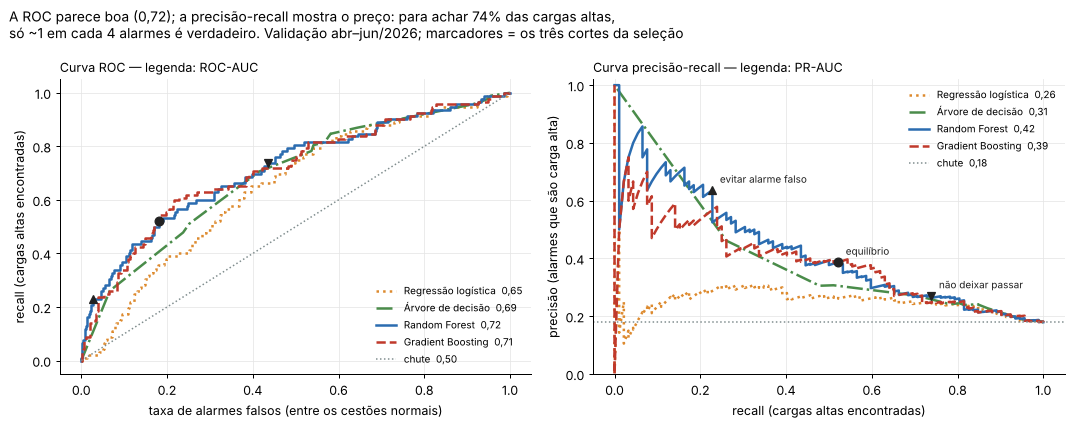

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for nome in ALGOS:
    fpr, tpr, _ = roc_curve(y_va, p_va[nome])
    axes[0].plot(fpr, tpr, ESTILO[nome], color=COR[nome], lw=2,
                 label=f"{nome}  {roc_auc_score(y_va, p_va[nome]):.2f}".replace(".", ","))
    prec, rec, _ = precision_recall_curve(y_va, p_va[nome])
    axes[1].plot(rec, prec, ESTILO[nome], color=COR[nome], lw=2,
                 label=f"{nome}  {average_precision_score(y_va, p_va[nome]):.2f}".replace(".", ","))
axes[0].plot([0, 1], [0, 1], color=CINZA, ls=":", lw=1.2, label="chute  0,50")
axes[1].axhline(y_va.mean(), color=CINZA, ls=":", lw=1.2, label=f"chute  {y_va.mean():.2f}".replace(".", ","))
# os três cortes da seleção, sobre a curva da Random Forest
for c, mk in zip(CENARIOS, ["v", "o", "^"]):
    prev = p_va_A >= LIM_A[c]
    r, pr = recall_score(y_va, prev), precision_score(y_va, prev)
    fp_rate = ((prev) & (y_va == 0)).sum() / (y_va == 0).sum()
    axes[0].plot(fp_rate, r, mk, color="#222", ms=7, zorder=5)
    axes[1].plot(r, pr, mk, color="#222", ms=7, zorder=5)
    axes[1].annotate(CURTO[c], (r, pr), xytext=(6, 6), textcoords="offset points", fontsize=8, color="#222")
axes[0].set_xlabel("taxa de alarmes falsos (entre os cestões normais)")
axes[0].set_ylabel("recall (cargas altas encontradas)")
axes[0].set_title("Curva ROC — legenda: ROC-AUC", loc="left", fontsize=10)
axes[1].set_xlabel("recall (cargas altas encontradas)")
axes[1].set_ylabel("precisão (alarmes que são carga alta)")
axes[1].set_title("Curva precisão-recall — legenda: PR-AUC", loc="left", fontsize=10)
axes[1].set_ylim(0, 1.02)
for ax in axes:
    ax.legend(fontsize=8, frameon=False, loc="lower right" if ax is axes[0] else "upper right")
prev_F2 = p_va_A >= LIM_A[CENARIOS[0]]
rec_F2, prec_F2 = recall_score(y_va, prev_F2), precision_score(y_va, prev_F2)
fig.suptitle(f"A ROC parece boa ({br(roc_auc_score(y_va, p_va_A))}); a precisão-recall mostra o preço: para achar "
             f"{100 * rec_F2:.0f}% das cargas altas,\nsó ~1 em cada {1 / prec_F2:.0f} alarmes é verdadeiro. "
             "Validação abr–jun/2026; marcadores = os três cortes da seleção", x=0.01, ha="left", fontsize=11)
salvar("02_curvas_roc_e_precisao_recall")

## 6. A matriz de confusão do modelo escolhido (slides 8 a 10, 19; passo 5)

Na validação, nos três cortes. **Atenção à ordem do scikit-learn (slide 10):** a saída de
`confusion_matrix` vem como `[[VN, FP], [FN, VP]]`, com a classe 0 ("normal") primeiro.

In [12]:
linhas = []
for c in CENARIOS:
    vn, fp, fn, vp = confusion_matrix(y_va, p_va_A >= LIM_A[c]).ravel()
    linhas.append({"corte": c, "limiar": LIM_A[c], "VP": vp, "FN": fn, "FP": fp, "VN": vn,
                   **metricas_no_corte(y_va, p_va_A, LIM_A[c])})
tab_matriz_val = pd.DataFrame(linhas).set_index("corte")
print(f"Validação: {len(y_va)} cestões, {int(y_va.sum())} cargas altas.\n")
print(f"classification_report no corte '{CURTO[CENARIOS[1]]}':")
print(classification_report(y_va, p_va_A >= LIM_A[CENARIOS[1]], target_names=["normal", "carga alta"], digits=2))
tab_matriz_val.round(3)

Validação: 513 cestões, 92 cargas altas.

classification_report no corte 'equilíbrio':
              precision    recall  f1-score   support

      normal       0.89      0.82      0.85       421
  carga alta       0.39      0.52      0.44        92

    accuracy                           0.77       513
   macro avg       0.64      0.67      0.65       513
weighted avg       0.80      0.77      0.78       513



,limiar,VP,FN,FP,VN,acurácia,precisão,recall,F1,alarmes/100
corte,,,,,,,,,,
não deixar passar (F2),0.350,68,24,183,238,0.596,0.271,0.739,0.397,48.928
equilíbrio (F1),0.537,48,44,76,345,0.766,0.387,0.522,0.444,24.172
"evitar alarme falso (F0,5)",0.745,21,71,12,409,0.838,0.636,0.228,0.336,6.433


## 7. O ponto de corte pelo custo do erro (slides 16 e 34; passo 6)

O slide 34 transforma erros em dinheiro: `custo = FN × custo_FN + FP × custo_FP`. Sem o custo
do alarme falso, medimos tudo **em alarmes falsos equivalentes**:

`custo a cada 100 cestões = FP + k × FN`, com `k = custo_FN ÷ custo_FP`.

Para cada `k`, escolhemos **na validação** o corte de menor custo e comparamos com as duas
"estratégias sem modelo": **nunca alarmar** (custa `k × cargas altas`) e **sempre alarmar**
(custa um alarme falso por cestão normal).

**Cuidado ao ler esta seção.** Na validação, o corte "ótimo" é procurado entre todos os cortes,
inclusive "nunca alarmar" e "alarmar tudo". Então o modelo **nunca** fica pior que as estratégias
sem modelo **na validação**, por construção, e a economia medida aqui é otimista (o corte foi
ajustado nos mesmos dados). A prova de verdade é aplicar esses cortes no teste (seção 11).
O que esta seção entrega é o **mapa**: para cada `k`, qual dos três cortes da seleção usar.

**Como a EVCOMX pode chegar no `k`.** Uma carga alta para o forno ~4 min em média (seção 1).
Se um alarme falso custar ~1 min de trabalho do pátio, e se um minuto de pátio valer o mesmo que
um minuto de forno parado, `k ≈ 4`. Se o minuto de forno valer mais (energia, produção perdida),
`k` sobe. A tabela abaixo diz qual dos três cortes da seleção é o mais barato para cada faixa de `k`.

Detalhe teórico: se a chance do modelo fosse "de verdade", o corte ideal seria `1 ÷ (1 + k)`.
Como a Random Forest usa `class_weight="balanced"`, as chances vêm infladas (seção 8) e o corte
precisa ser medido, não calculado.

In [13]:
def custo_por_100(y, p, lim, k):
    prev = p >= lim
    fp = (prev & (y == 0)).sum()
    fn = (~prev & (y == 1)).sum()
    return 100 * (fp + k * fn) / len(y)

def corte_otimo(y, p, k):
    lims = np.unique(np.concatenate([p, [np.inf]]))
    custos = [custo_por_100(y, p, l, k) for l in lims]
    i = int(np.argmin(custos))
    return lims[i], custos[i]

KS = np.round(np.arange(1, 12.01, 0.25), 2)
yv = y_va.to_numpy()
linhas = []
for k in KS:
    lim, c_mod = corte_otimo(yv, p_va_A, k)
    linhas.append({"k": k, "limiar_otimo": lim, "custo_modelo": c_mod,
                   "custo_nunca_alarmar": 100 * k * yv.mean(), "custo_sempre_alarmar": 100 * (1 - yv.mean()),
                   **{f"custo {CURTO[c]}": custo_por_100(yv, p_va_A, LIM_A[c], k) for c in CENARIOS},
                   **{f"{m} no ótimo": v for m, v in metricas_no_corte(yv, p_va_A, lim).items() if m in ("recall", "precisão", "alarmes/100")}})
tab_custo = pd.DataFrame(linhas)
tab_custo["custo_sem_modelo"] = tab_custo[["custo_nunca_alarmar", "custo_sempre_alarmar"]].min(axis=1)
tab_custo["economia_%"] = 100 * (1 - tab_custo["custo_modelo"] / tab_custo["custo_sem_modelo"])
tab_custo["melhor_dos_3_cortes"] = tab_custo[[f"custo {CURTO[c]}" for c in CENARIOS]].idxmin(axis=1).str.replace("custo ", "")

# faixas de k em que cada um dos três cortes da seleção é o mais barato
faixas_k = tab_custo.groupby("melhor_dos_3_cortes")["k"].agg(["min", "max"]).reindex([CURTO[c] for c in CENARIOS])
print("Em que faixa de k cada corte da seleção é o mais barato (validação):")
print(faixas_k.to_string(), "\n")
K_MOSTRAR = [1, 2, 3, 4, 5, 6, 8, 10, 12]
tab_custo[tab_custo.k.isin(K_MOSTRAR)].set_index("k")[
    ["limiar_otimo", "recall no ótimo", "precisão no ótimo", "alarmes/100 no ótimo",
     "custo_modelo", "custo_sem_modelo", "economia_%", "melhor_dos_3_cortes"]].round(2)

Em que faixa de k cada corte da seleção é o mais barato (validação):
                     min    max
melhor_dos_3_cortes            
não deixar passar    5.5  12.00
equilíbrio           2.5   5.25
evitar alarme falso  1.0   2.25 



,limiar_otimo,recall no ótimo,precisão no ótimo,alarmes/100 no ótimo,custo_modelo,custo_sem_modelo,economia_%,melhor_dos_3_cortes
k,,,,,,,,
1.0,0.74,0.23,0.64,6.43,16.18,17.93,9.78,evitar alarme falso
2.0,0.60,0.43,0.44,17.54,30.02,35.87,16.30,evitar alarme falso
3.0,0.60,0.43,0.44,17.54,40.16,53.80,25.36,equilíbrio
4.0,0.53,0.53,0.38,25.15,49.12,71.73,31.52,equilíbrio
5.0,0.50,0.57,0.36,28.46,57.31,82.07,30.17,equilíbrio
6.0,0.32,0.79,0.27,53.61,61.60,82.07,24.94,não deixar passar
8.0,0.32,0.80,0.26,55.17,68.81,82.07,16.15,não deixar passar
10.0,0.31,0.82,0.26,57.31,75.83,82.07,7.60,não deixar passar
12.0,0.10,0.99,0.19,94.74,79.34,82.07,3.33,não deixar passar


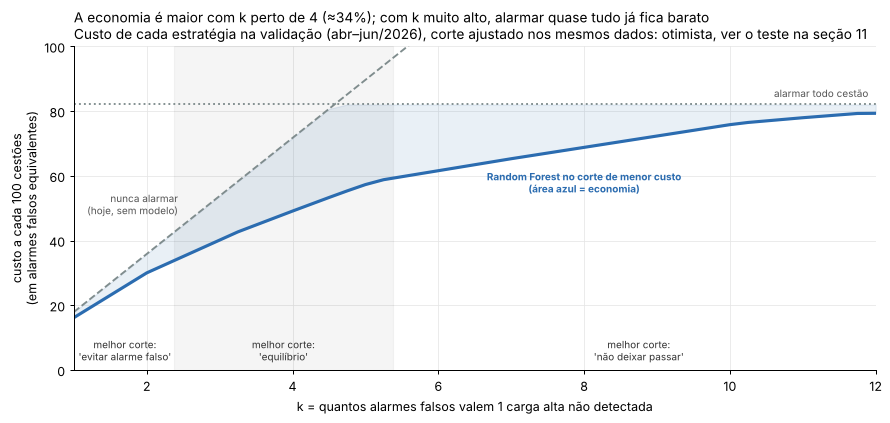

In [14]:
# Gráfico 03: custo a cada 100 cestões conforme k
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(tab_custo.k, tab_custo.custo_nunca_alarmar, color=CINZA, ls="--", lw=1.5)
ax.plot(tab_custo.k, tab_custo.custo_sempre_alarmar, color=CINZA, ls=":", lw=1.5)
ax.plot(tab_custo.k, tab_custo.custo_modelo, color=AZUL, lw=2.5)
ax.fill_between(tab_custo.k, tab_custo.custo_modelo, tab_custo.custo_sem_modelo, color=AZUL, alpha=0.10)
ax.annotate("nunca alarmar\n(hoje, sem modelo)", (2.6, 100 * 2.6 * yv.mean()), xytext=(-10, 4),
            textcoords="offset points", fontsize=8, color="#555", ha="right")
ax.annotate("alarmar todo cestão", (11.9, 100 * (1 - yv.mean())), xytext=(0, 6), textcoords="offset points",
            fontsize=8, color="#555", ha="right")
k_dir = 8
c_dir = float(tab_custo.loc[tab_custo.k == k_dir, "custo_modelo"].iloc[0])
ax.annotate("Random Forest no corte de menor custo\n(área azul = economia)", (k_dir, c_dir), xytext=(0, -36),
            textcoords="offset points", fontsize=8, color=AZUL, fontweight="bold", ha="center")
for c, alpha in zip(CENARIOS, [0.0, 0.04, 0.0]):
    lo, hi = faixas_k.loc[CURTO[c]]
    if pd.notna(lo):
        ax.axvspan(max(lo - 0.125, 1), min(hi + 0.125, 12), color="#000", alpha=alpha)
        ax.annotate(f"melhor corte:\n'{CURTO[c]}'", (max((max(lo, 1) + min(hi, 12)) / 2, 1.7), 3), ha="center",
                    fontsize=8, color="#333")
ax.set_xlim(1, 12)
ax.set_ylim(0, 100)
ax.set_xlabel("k = quantos alarmes falsos valem 1 carga alta não detectada")
ax.set_ylabel("custo a cada 100 cestões\n(em alarmes falsos equivalentes)")
eco = tab_custo.set_index("k")["economia_%"]
ax.set_title(f"A economia é maior com k perto de {eco.idxmax():.0f} (≈{eco.max():.0f}%); com k muito alto, alarmar quase "
             "tudo já fica barato\nCusto de cada estratégia na validação (abr–jun/2026), corte ajustado nos mesmos "
             "dados: otimista, ver o teste na seção 11", loc="left", fontsize=11)
salvar("03_custo_conforme_k")

## 8. A "chance" do modelo é chance de verdade? (calibração)

A seleção mostra uma **chance de carga alta** por cestão. Para o pátio, "chance de 40%" deveria
querer dizer "4 em cada 10 cestões assim dão carga alta". Isso se chama **calibração**.

O `class_weight="balanced"` ajuda o modelo a prestar atenção na classe rara, mas **infla** as
chances. Medimos isso de duas formas:
- **média da chance prevista** contra a taxa real;
- **Brier score**: erro quadrático médio da chance (menor é melhor). A referência é o Brier de
  quem sempre diz "a taxa média".

A saída prática: em vez de mostrar a chance crua, o pátio vê **faixas de risco** com a taxa
real observada em cada uma. As fronteiras das faixas são os três cortes da seleção.

In [15]:
tab_calib = pd.DataFrame({
    conj: {"taxa real": y.mean(), "chance média prevista": p.mean(),
           "Brier do modelo": brier_score_loss(y, p), "Brier de 'sempre a taxa do treino'": brier_score_loss(y, np.full(len(y), y_tr.mean()))}
    for conj, y, p in [("validação", y_va, p_va_A), ("teste", y_te, p_te_A)]}).T
razao = tab_calib["chance média prevista"] / tab_calib["taxa real"]
print(f"A chance prevista é {br(razao.min(), 1)} a {br(razao.max(), 1)} vezes a taxa real: o modelo ordena bem, "
      "mas a 'chance' não é chance.")
pior = (tab_calib["Brier do modelo"] > tab_calib["Brier de 'sempre a taxa do treino'"]).all()
print("O Brier do modelo é " + ("pior" if pior else "melhor") + " que o da referência"
      + (": as chances cruas não devem ser mostradas como probabilidade.\n" if pior else ".\n"))
print(tab_calib.round(3).to_string())

FRONTEIRAS = [0] + [LIM_A[c] for c in CENARIOS] + [1.0001]
NOMES_FAIXA = ["baixo", "atenção", "alto", "muito alto"]
def tabela_faixas(y, p):
    f = pd.cut(p, FRONTEIRAS, labels=NOMES_FAIXA, right=False)
    t = pd.DataFrame({"faixa": f, "y": np.asarray(y)}).groupby("faixa", observed=False)["y"].agg(["size", "sum", "mean"])
    t.columns = ["cestões", "cargas altas", "taxa real"]
    t["% dos cestões"] = 100 * t["cestões"] / t["cestões"].sum()
    t["% das cargas altas"] = 100 * t["cargas altas"] / t["cargas altas"].sum()
    return t
faixas = pd.concat({"validação": tabela_faixas(y_va, p_va_A), "teste": tabela_faixas(y_te, p_te_A)}, axis=1)
faixas.insert(0, ("", "chance prevista"), [f"{a:.2f}–{min(b, 1):.2f}".replace(".", ",") for a, b in zip(FRONTEIRAS[:-1], FRONTEIRAS[1:])])
faixas.round(3)

A chance prevista é 2,1 a 2,4 vezes a taxa real: o modelo ordena bem, mas a 'chance' não é chance.
O Brier do modelo é pior que o da referência: as chances cruas não devem ser mostradas como probabilidade.

           taxa real  chance média prevista  Brier do modelo  Brier de 'sempre a taxa do treino'
validação      0.179                  0.385            0.181                               0.148
teste          0.146                  0.351            0.162                               0.125


validação                                                           teste                                                        
           chance prevista   cestões cargas altas taxa real % dos cestões % das cargas altas cestões cargas altas taxa real % dos cestões % das cargas altas
faixa                                                                                                                                                       
baixo            0,00–0,35       262           24     0.092        51.072             26.087     296           15     0.051        57.476             20.000
atenção          0,35–0,54       127           20     0.157        24.756             21.739     114           23     0.202        22.136             30.667
alto             0,54–0,74        91           27     0.297        17.739             29.348      60           19     0.317        11.650             25.333
muito alto       0,74–1,00        33           21     0.636         6.433             22.826      45           18     0.400         8.738             24.000

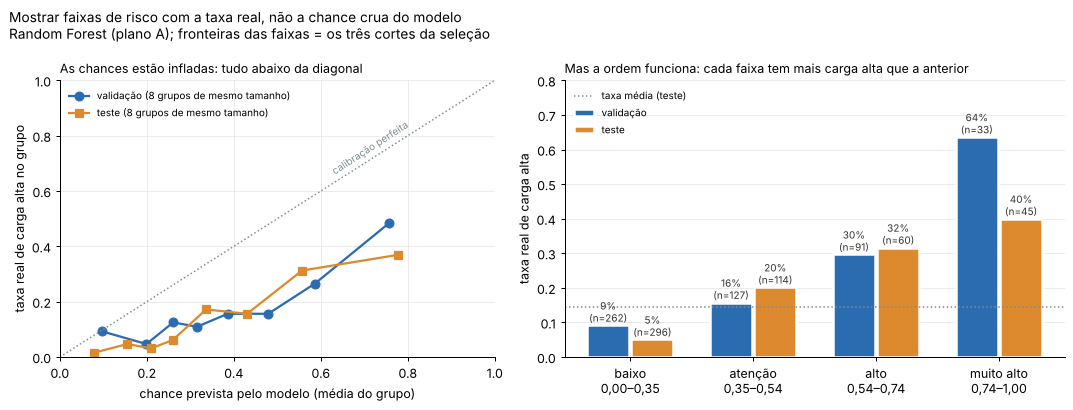

In [16]:
# Gráfico 04: calibração (esquerda) e faixas de risco (direita)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1, 1.15]})
ax = axes[0]
for conj, y, p, cor, mk in [("validação", y_va, p_va_A, AZUL, "o"), ("teste", y_te, p_te_A, LARANJA, "s")]:
    q = pd.qcut(p, 8, duplicates="drop")
    g = pd.DataFrame({"p": p, "y": np.asarray(y), "q": q}).groupby("q", observed=True).agg(p=("p", "mean"), y=("y", "mean"), n=("y", "size"))
    ax.plot(g.p, g.y, "-" + mk, color=cor, lw=1.8, ms=7, label=f"{conj} (8 grupos de mesmo tamanho)")
ax.plot([0, 1], [0, 1], color=CINZA, ls=":", lw=1.2)
ax.annotate("calibração perfeita", (0.62, 0.66), rotation=33, fontsize=8, color=CINZA)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel("chance prevista pelo modelo (média do grupo)")
ax.set_ylabel("taxa real de carga alta no grupo")
ax.set_title("As chances estão infladas: tudo abaixo da diagonal", loc="left", fontsize=10)
ax.legend(fontsize=8, frameon=False, loc="upper left")

ax = axes[1]
x = np.arange(len(NOMES_FAIXA))
for desl, conj, cor in [(-0.18, "validação", AZUL), (0.18, "teste", LARANJA)]:
    v = faixas[(conj, "taxa real")].to_numpy(dtype=float)
    ax.bar(x + desl, v, width=0.34, color=cor, label=conj, edgecolor="white", linewidth=2)
    for xi, vi, n in zip(x + desl, v, faixas[(conj, "cestões")]):
        ax.annotate(f"{100 * vi:.0f}%\n(n={n})", (xi, vi), xytext=(0, 3), textcoords="offset points",
                    ha="center", fontsize=8, color="#333")
ax.axhline(y_te.mean(), color=CINZA, ls=":", lw=1.2, label="taxa média (teste)")
ax.set_xticks(x, [f"{n}\n{c}" for n, c in zip(NOMES_FAIXA, faixas[("", "chance prevista")])])
ax.set_ylim(0, 0.8)
ax.set_ylabel("taxa real de carga alta")
ax.set_title("Mas a ordem funciona: cada faixa tem mais carga alta que a anterior", loc="left", fontsize=10)
ax.legend(fontsize=8, frameon=False, loc="upper left")
ax.grid(axis="x", visible=False)
fig.suptitle("Mostrar faixas de risco com a taxa real, não a chance crua do modelo\n"
             f"Random Forest (plano A); fronteiras das faixas = os três cortes da seleção",
             x=0.01, ha="left", fontsize=11)
salvar("04_calibracao_e_faixas_de_risco")

## 9. O desempenho se mantém no tempo? (slide 36: "ignorar a variação")

Uma nota só esconde a variação. Medimos o plano A **por período**, na validação e no teste, e
mostramos também as 5 provas da CV temporal dentro do treino (chances já calculadas na seção 4).
Os últimos dias de abril (49 cestões, já validação) foram somados a maio, e agosto (12 cestões)
a julho: períodos muito pequenos dariam notas sem sentido.

A PR-AUC de um chute é a taxa de carga alta do período, então as duas linhas ficam na mesma
escala: o que importa é a **distância** entre elas. Cada ponto vem com o **IC 90%** (*bootstrap*
por corrida): com 20 a 80 cargas altas por período, a nota de um mês sozinho é bem incerta.

In [17]:
fora = pd.concat([valid.assign(p=p_va_A), teste.assign(p=p_te_A)], ignore_index=True)
mes = fora["inicio"].dt.tz_convert("America/Sao_Paulo").dt.strftime("%Y-%m")
fora["periodo"] = mes.map({"2026-04": "fim abr–mai/26", "2026-05": "fim abr–mai/26", "2026-06": "jun/26",
                           "2026-07": "jul–ago/26", "2026-08": "jul–ago/26"})
assert fora["periodo"].notna().all()
LIM_F2 = LIM_A[CENARIOS[0]]

def linha_periodo(nome, origem, base, y, p):
    lo, hi = ic90(y, p, average_precision_score, amostras_bootstrap(base.reset_index(drop=True), n=500))
    return {"período": nome, "origem": origem, "cestões": len(y), "cargas altas": int(np.sum(y)), "taxa": np.mean(y),
            "PR-AUC": average_precision_score(y, p), "IC90 baixo": lo, "IC90 alto": hi}

linhas = []
for i, (a, b) in enumerate(CV, 1):
    ini, fim = treino.loc[b, "inicio"].min().tz_convert("America/Sao_Paulo"), treino.loc[b, "inicio"].max().tz_convert("America/Sao_Paulo")
    linhas.append(linha_periodo(f"prova {i}\n{ini:%d/%m}–{fim:%d/%m}", "CV no treino", treino.loc[b],
                                y_tr[b].to_numpy(), P_CV[("Random Forest", i)]))
for per, g in fora.groupby("periodo", sort=False):
    prev = g.p >= LIM_F2
    linhas.append({**linha_periodo(per, "validação + teste", g, g.carga_alta.to_numpy(), g.p.to_numpy()),
                   "recall (F2)": recall_score(g.carga_alta, prev), "precisão (F2)": precision_score(g.carga_alta, prev),
                   "alarmes/100 (F2)": 100 * prev.mean()})
tab_mes = pd.DataFrame(linhas)
tab_mes["PR-AUC ÷ chute"] = tab_mes["PR-AUC"] / tab_mes["taxa"]
tab_mes["acima do chute com folga"] = tab_mes["IC90 baixo"] > tab_mes["taxa"]
print(f"Em {tab_mes['acima do chute com folga'].sum()} de {len(tab_mes)} períodos, até o limite baixo do IC 90% "
      "fica acima do chute.")
tab_mes.round(3)

Em 8 de 8 períodos, até o limite baixo do IC 90% fica acima do chute.


,período,origem,cestões,cargas altas,taxa,PR-AUC,IC90 baixo,IC90 alto,recall (F2),precisão (F2),alarmes/100 (F2),PR-AUC ÷ chute,acima do chute com folga
0,prova 1\n26/09–26/10,CV no treino,417,39,0.094,0.324,0.223,0.472,NaN,NaN,NaN,3.465,True
1,prova 2\n26/10–29/11,CV no treino,409,78,0.191,0.585,0.501,0.699,NaN,NaN,NaN,3.069,True
2,prova 3\n29/11–23/01,CV no treino,415,71,0.171,0.414,0.337,0.517,NaN,NaN,NaN,2.421,True
3,prova 4\n23/01–13/03,CV no treino,416,52,0.125,0.402,0.321,0.529,NaN,NaN,NaN,3.214,True
4,prova 5\n13/03–25/04,CV no treino,409,73,0.178,0.254,0.211,0.328,NaN,NaN,NaN,1.421,True
5,fim abr–mai/26,validação + teste,196,29,0.148,0.280,0.194,0.429,0.621,0.222,41.327,1.891,True
6,jun/26,validação + teste,446,78,0.175,0.393,0.325,0.502,0.744,0.269,48.430,2.249,True
7,jul–ago/26,validação + teste,386,60,0.155,0.414,0.335,0.510,0.867,0.301,44.819,2.667,True


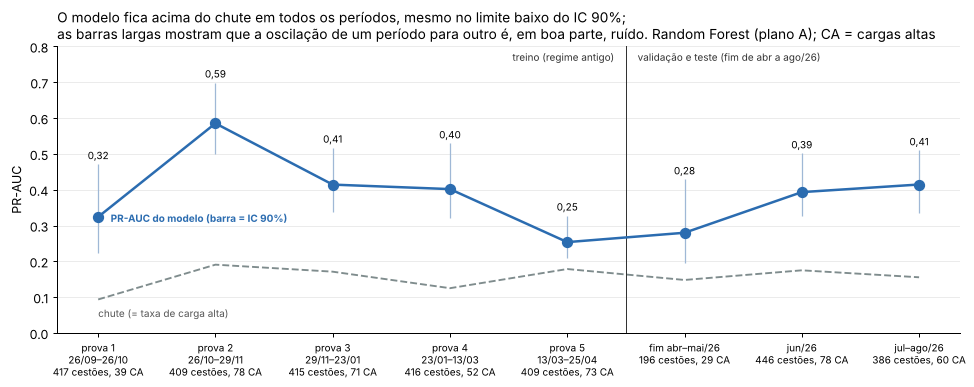

In [18]:
# Gráfico 05: PR-AUC por período contra o chute
fig, ax = plt.subplots(figsize=(11, 4.4))
x = np.arange(len(tab_mes))
ax.errorbar(x, tab_mes["PR-AUC"], yerr=[tab_mes["PR-AUC"] - tab_mes["IC90 baixo"], tab_mes["IC90 alto"] - tab_mes["PR-AUC"]],
            fmt="-o", color=AZUL, lw=2, ms=8, elinewidth=1, ecolor="#9fb8d6", capsize=0)
ax.plot(x, tab_mes["taxa"], "--", color=CINZA, lw=1.5)
for xi, v, hi in zip(x, tab_mes["PR-AUC"], tab_mes["IC90 alto"]):
    ax.annotate(br(v), (xi, hi), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=8)
ax.annotate("PR-AUC do modelo (barra = IC 90%)", (x[0], tab_mes["PR-AUC"].iloc[0]), xytext=(10, -4),
            textcoords="offset points", fontsize=8, color=AZUL, fontweight="bold")
ax.annotate("chute (= taxa de carga alta)", (x[0], tab_mes["taxa"].iloc[0]), xytext=(0, -14), textcoords="offset points",
            fontsize=8, color="#555")
n_cv = (tab_mes.origem == "CV no treino").sum()
ax.axvline(n_cv - 0.5, color="#333", lw=0.8)
ax.annotate("treino (regime antigo)", (n_cv - 0.6, 0.76), ha="right", fontsize=8, color="#333")
ax.annotate("validação e teste (fim de abr a ago/26)", (n_cv - 0.4, 0.76), ha="left", fontsize=8, color="#333")
ax.set_xticks(x, [f"{p}\n{n} cestões, {c} CA" for p, n, c in zip(tab_mes["período"], tab_mes["cestões"],
                                                                tab_mes["cargas altas"])], fontsize=8)
ax.set_ylim(0, 0.8)
ax.set_ylabel("PR-AUC")
n_folga = int(tab_mes["acima do chute com folga"].sum())
n_acima = int((tab_mes["PR-AUC"] > tab_mes["taxa"]).sum())
acima = ("em todos os períodos, mesmo no limite baixo do IC 90%" if n_folga == len(tab_mes)
         else f"em {n_acima} de {len(tab_mes)} períodos ({n_folga} mesmo no limite baixo do IC 90%)")
ax.set_title(f"O modelo fica acima do chute {acima};\nas barras largas mostram que a oscilação de um período para "
             "outro é, em boa parte, ruído. Random Forest (plano A); CA = cargas altas", loc="left", fontsize=11)
ax.grid(axis="x", visible=False)
salvar("05_estabilidade_no_tempo")

## 10. Minutos de parada: o modelo pega as cargas altas que mais doem?

Nem toda carga alta custa igual: a parada vai de segundos a 20 minutos. Se o modelo pegar
justamente as longas, ele vale mais do que o recall sugere; se pegar só as curtas, vale menos.

**Recall em minutos** = minutos de parada dos cestões que receberam alarme ÷ minutos de parada
de todas as cargas altas.

In [19]:
linhas = []
for conj, base, p in [("validação", valid, p_va_A), ("teste", teste, p_te_A)]:
    ca = base.carga_alta.to_numpy() == 1
    seg = base.seg_parada.to_numpy()
    for c in CENARIOS:
        alarme = p >= LIM_A[c]
        linhas.append({"conjunto": conj, "corte": CURTO[c], "recall (eventos)": (alarme & ca).sum() / ca.sum(),
                       "recall (minutos de parada)": seg[alarme & ca].sum() / seg[ca].sum(),
                       "parada mediana pega (min)": np.median(seg[alarme & ca]) / 60,
                       "parada mediana perdida (min)": np.median(seg[~alarme & ca]) / 60})
tab_minutos = pd.DataFrame(linhas).set_index(["conjunto", "corte"])

# as medianas acima variam muito com poucos casos; dois testes com todas as cargas altas de validação + teste
from scipy.stats import spearmanr, mannwhitneyu
eh_ca = np.concatenate([y_va, y_te]) == 1
p_ca = np.concatenate([p_va_A, p_te_A])[eh_ca]
seg_ca = np.concatenate([valid.seg_parada, teste.seg_parada])[eh_ca]
rho, p_rho = spearmanr(p_ca, seg_ca)
pegas = p_ca >= LIM_F2
mw = mannwhitneyu(seg_ca[pegas], seg_ca[~pegas])
print(f"Cargas altas de validação + teste: {eh_ca.sum()}.")
print(f"Spearman entre a chance prevista e a duração: {rho:.2f} (p = {p_rho:.2f}).")
print(f"Duração das pegas × perdidas no corte '{CURTO[CENARIOS[0]]}' (Mann-Whitney): p = {mw.pvalue:.2f}.")
print("Sem diferença clara: o modelo não separa bem paradas longas de curtas, e o recall em minutos fica "
      "perto do recall em eventos.\n")
tab_minutos.round(2)

Cargas altas de validação + teste: 167.
Spearman entre a chance prevista e a duração: 0.09 (p = 0.23).
Duração das pegas × perdidas no corte 'não deixar passar' (Mann-Whitney): p = 0.23.
Sem diferença clara: o modelo não separa bem paradas longas de curtas, e o recall em minutos fica perto do recall em eventos.



recall (eventos)  recall (minutos de parada)  parada mediana pega (min)  parada mediana perdida (min)
conjunto  corte                                                                                                                     
validação não deixar passar                0.74                        0.73                       3.32                          2.07
          equilíbrio                       0.52                        0.49                       3.15                          2.72
          evitar alarme falso              0.23                        0.24                       3.45                          2.87
teste     não deixar passar                0.80                        0.84                       2.16                          1.53
          equilíbrio                       0.49                        0.51                       2.08                          2.19
          evitar alarme falso              0.24                        0.33                       2.30                          1.98

## 11. Conferência no teste, traduzida para a operação (slides 34 e 37; passo 7)

O teste (jun–ago/2026) já foi usado **uma única vez** na seleção. Aqui ele não escolhe nada:
os cortes vieram da validação. Só traduzimos o resultado para a língua do pátio e da gestão:
**a cada 100 cestões** e **a cada 30 dias de operação** (no ritmo de cestões do teste).

A coluna "minutos de parada cobertos" supõe que um alarme certo permite **evitar** a carga alta
(ver seção 1). É um teto do ganho, não uma promessa.

In [20]:
CESTOES_30D = len(teste) / dias["teste"] * 30
linhas = []
for plano, p, lims in [("A (com histórico)", p_te_A, LIM_A), ("B (sem histórico)", p_te_B, LIM_B)]:
    for c in CENARIOS:
        alarme = p >= lims[c]
        ca = y_te.to_numpy() == 1
        vn, fp, fn, vp = confusion_matrix(y_te, alarme).ravel()
        linhas.append({"plano": plano, "corte": CURTO[c], "limiar": lims[c],
                       "PR-AUC": average_precision_score(y_te, p), "ROC-AUC": roc_auc_score(y_te, p),
                       "recall": vp / (vp + fn), "precisão": vp / max(vp + fp, 1),
                       "alarmes/100": 100 * alarme.mean(), "VP/100": 100 * vp / len(y_te), "FN/100": 100 * fn / len(y_te),
                       "FP/100": 100 * fp / len(y_te),
                       "alarmes falsos por acerto": fp / max(vp, 1),
                       "min. de parada cobertos /30 dias": teste.seg_parada.to_numpy()[alarme & ca].sum() / 60 / dias["teste"] * 30,
                       "min. de parada perdidos /30 dias": teste.seg_parada.to_numpy()[~alarme & ca].sum() / 60 / dias["teste"] * 30})
tab_teste = pd.DataFrame(linhas).set_index(["plano", "corte"])

# conferência com a seleção: os limiares do JSON têm 4 casas; o resultado no teste tem de ser o mesmo
res_sel = pd.read_csv(PASTA_SEL / "resultado_teste.csv")
res_sel = res_sel[res_sel.plano != "baseline"].assign(corte=lambda d: d.cenario.map(CURTO)).set_index(["plano", "corte"])
for col_aqui, col_sel in [("recall", "recall"), ("precisão", "precisao"), ("alarmes/100", "alarmes_por_100")]:
    assert np.allclose(tab_teste[col_aqui], res_sel.loc[tab_teste.index, col_sel]), f"{col_aqui} difere da seleção"
print("Conferência OK: recall, precisão e alarmes no teste iguais aos de selecao_algoritmos/resultado_teste.csv\n")
print(f"Teste: {len(y_te)} cestões em {dias['teste']:.0f} dias (~{CESTOES_30D:.0f} cestões a cada 30 dias), "
      f"{int(y_te.sum())} cargas altas ({100 * y_te.mean():.1f} por 100 cestões).")
print(f"Sem modelo, todas as {tab_parada.loc['teste', 'total_min_por_30_dias']:.0f} min de parada a cada 30 dias passam.")
p_regra_te = regra(teste, "taxa_ca_ult5")
print(f"Referências no teste: regra 'só histórico' PR-AUC {average_precision_score(y_te, p_regra_te):.3f} e "
      f"recall c/ 20 alarmes por 100 {recall_no_orcamento(y_te, p_regra_te):.2f}; "
      f"Random Forest {average_precision_score(y_te, p_te_A):.3f} e {recall_no_orcamento(y_te, p_te_A):.2f}.\n")
tab_teste.round(2)

Conferência OK: recall, precisão e alarmes no teste iguais aos de selecao_algoritmos/resultado_teste.csv

Teste: 515 cestões em 41 dias (~379 cestões a cada 30 dias), 75 cargas altas (14.6 por 100 cestões).
Sem modelo, todas as 185 min de parada a cada 30 dias passam.
Referências no teste: regra 'só histórico' PR-AUC 0.358 e recall c/ 20 alarmes por 100 0.56; Random Forest 0.354 e 0.48.



limiar  PR-AUC  ROC-AUC  recall  precisão  alarmes/100  VP/100  FN/100  FP/100  alarmes falsos por acerto  \
plano             corte                                                                                                                            
A (com histórico) não deixar passar      0.35    0.35     0.77    0.80      0.27        42.52   11.65    2.91   30.87                       2.65   
                  equilíbrio             0.54    0.35     0.77    0.49      0.35        20.39    7.18    7.38   13.20                       1.84   
                  evitar alarme falso    0.74    0.35     0.77    0.24      0.40         8.74    3.50   11.07    5.24                       1.50   
B (sem histórico) não deixar passar      0.38    0.20     0.61    0.59      0.18        46.21    8.54    6.02   37.67                       4.41   
                  equilíbrio             0.51    0.20     0.61    0.39      0.22        25.63    5.63    8.93   20.00                       3.55   
                  evitar alarme falso    0.64    0.20     0.61    0.19      0.23        11.65    2.72   11.84    8.93                       3.29   

                                       min. de parada cobertos /30 dias  min. de parada perdidos /30 dias  
plano             corte                                                                                    
A (com histórico) não deixar passar                              155.33                             29.42  
                  equilíbrio                                      93.59                             91.16  
                  evitar alarme falso                             60.48                            124.27  
B (sem histórico) não deixar passar                              125.66                             59.10  
                  equilíbrio                                      94.99                             89.76  
                  evitar alarme falso                             44.22                            140.53

### O modelo supera a regra do histórico no teste?

Mesmo *bootstrap* pareado da seção 4, agora no teste. **Não escolhe nada**: o modelo já está
decidido. Serve para responder com honestidade a pergunta "precisava de um modelo?".

In [21]:
BOOT_TE = amostras_bootstrap(teste)
yt = y_te.to_numpy()
linhas = []
for nome, pc in [("Regra: mais taxa_ca_ult5 (só histórico)", p_regra_te), ("Random Forest plano B (sem histórico)", p_te_B)]:
    for met, func in [("PR-AUC", average_precision_score), ("recall 20/100", recall_no_orcamento)]:
        dif = np.array([func(yt[a], p_te_A[a]) - func(yt[a], pc[a]) for a in BOOT_TE])
        linhas.append({"Random Forest (plano A) contra": nome, "métrica": met,
                       "diferença": func(yt, p_te_A) - func(yt, pc),
                       "IC90 da diferença": f"{np.percentile(dif, 5):+.2f} a {np.percentile(dif, 95):+.2f}",
                       "% dos sorteios em que a RF vence": 100 * (dif > 0).mean()})
tab_pareada_teste = pd.DataFrame(linhas).set_index(["Random Forest (plano A) contra", "métrica"])
tab_pareada_teste["leitura"] = tab_pareada_teste["% dos sorteios em que a RF vence"].map(veredito)
tab_pareada_teste.round(3)

diferença IC90 da diferença  % dos sorteios em que a RF vence           leitura
Random Forest (plano A) contra          métrica                                                                                       
Regra: mais taxa_ca_ult5 (só histórico) PR-AUC            -0.003     -0.06 a +0.07                              52.9            empate
                                        recall 20/100     -0.078     -0.18 a -0.01                               3.7  desvantagem real
Random Forest plano B (sem histórico)   PR-AUC             0.152     +0.10 a +0.21                             100.0     vantagem real
                                        recall 20/100      0.133     +0.05 a +0.24                              99.4     vantagem real

**Leitura (o achado mais importante desta etapa).** Se a Random Forest não tiver vantagem real
sobre a regra "só histórico" no teste, então:
- o sinal mais forte, e o mais estável, é o **histórico do forno** ("carga alta puxa carga alta");
- a **composição do cestão** contribui (o plano B, sem histórico, fica acima do chute, e o plano A
  supera o plano B), mas, no regime pós-maio, ainda **não se mostrou maior** do que a regra simples
  do histórico.

Isso não invalida o modelo. Muda **o que dizer** à EVCOMX: a régua honesta não é o chute, é a
regra do histórico.

### E o modelo para uso (treino + validação)?

Os `.joblib` da seleção foram re-treinados em **treino + validação**. O teste vem **depois** dos
dois, então medir esses modelos no teste é legítimo: é a nota de quem vai de fato para a
operação, e não muda nenhuma escolha (algoritmo, features e limiares já estão fixos).

Duas perguntas:
1. Ter visto abril–junho (o começo do regime novo) ajuda o modelo a superar a regra do histórico?
2. Os limiares, escolhidos com o modelo treinado só no treino, **valem** para o modelo re-treinado?
   Um limiar é um número de chance; se o modelo novo der chances em outra escala, o mesmo limiar
   dispara outra quantidade de alarmes.

In [22]:
import joblib
uso = {}
for plano, cols in [("A", COLS_A), ("B", COLS_B)]:
    m = joblib.load(PASTA_SEL / f"modelo_final_plano{plano}.joblib")
    assert list(m.feature_names_in_) == cols, f"O joblib do plano {plano} não usa as features do modelo_final.json"
    uso[plano] = m.predict_proba(teste[cols])[:, 1]

linhas = []
for nome, p in [("RF plano A, treinada só no treino (avaliada até aqui)", p_te_A),
                ("RF plano A para uso (treino + validação)", uso["A"]),
                ("RF plano B para uso (treino + validação)", uso["B"]),
                ("Regra: mais taxa_ca_ult5 (só histórico)", p_regra_te)]:
    linhas.append({"modelo": nome, "PR-AUC": average_precision_score(yt, p), "ROC-AUC": roc_auc_score(yt, p),
                   "recall c/ 20 alarmes por 100": recall_no_orcamento(yt, p)})
tab_uso = pd.DataFrame(linhas).set_index("modelo")

linhas = []
for met, func in [("PR-AUC", average_precision_score), ("recall 20/100", recall_no_orcamento)]:
    dif = np.array([func(yt[a], uso["A"][a]) - func(yt[a], p_regra_te[a]) for a in BOOT_TE])
    linhas.append({"métrica": met, "diferença": func(yt, uso["A"]) - func(yt, p_regra_te),
                   "IC90 da diferença": f"{np.percentile(dif, 5):+.2f} a {np.percentile(dif, 95):+.2f}",
                   "% dos sorteios em que a RF vence": 100 * (dif > 0).mean()})
tab_uso_regra = pd.DataFrame(linhas).set_index("métrica")
tab_uso_regra["leitura"] = tab_uso_regra["% dos sorteios em que a RF vence"].map(veredito)

linhas = []
for c in CENARIOS:
    for nome, p in [("treinada só no treino", p_te_A), ("para uso (treino + validação)", uso["A"])]:
        linhas.append({"corte": CURTO[c], "limiar": LIM_A[c], "modelo": nome, **{
            k: v for k, v in metricas_no_corte(yt, p, LIM_A[c]).items() if k in ("recall", "precisão", "alarmes/100")}})
tab_uso_limiar = pd.DataFrame(linhas).set_index(["corte", "modelo"])

print("1) No teste: modelo para uso contra a regra do histórico")
print(tab_uso.round(3).to_string(), "\n")
print(tab_uso_regra.round(3).to_string(), "\n")
print("2) Os mesmos limiares nos dois modelos (teste)")
print(f"Chance média prevista: treinada só no treino {p_te_A.mean():.2f}; para uso {uso['A'].mean():.2f}; "
      f"taxa real {yt.mean():.2f}.")
tab_uso_limiar.round(3)

1) No teste: modelo para uso contra a regra do histórico
                                                       PR-AUC  ROC-AUC  recall c/ 20 alarmes por 100
modelo                                                                                              
RF plano A, treinada só no treino (avaliada até aqui)   0.354    0.767                         0.480
RF plano A para uso (treino + validação)                0.372    0.796                         0.533
RF plano B para uso (treino + validação)                0.198    0.617                         0.267
Regra: mais taxa_ca_ult5 (só histórico)                 0.358    0.790                         0.558 

               diferença IC90 da diferença  % dos sorteios em que a RF vence leitura
métrica                                                                             
PR-AUC             0.014     -0.04 a +0.09                              66.4  empate
recall 20/100     -0.025     -0.13 a +0.05                              27.0  em

limiar  precisão  recall  alarmes/100
corte               modelo                                                              
não deixar passar   treinada só no treino           0.350     0.274   0.800       42.524
                    para uso (treino + validação)   0.350     0.303   0.760       36.505
equilíbrio          treinada só no treino           0.537     0.352   0.493       20.388
                    para uso (treino + validação)   0.537     0.407   0.440       15.728
evitar alarme falso treinada só no treino           0.745     0.400   0.240        8.738
                    para uso (treino + validação)   0.745     0.379   0.147        5.631

**Leitura.**
- Se o modelo para uso continuar sem vantagem real sobre a regra do histórico, o re-treino com
  abril–junho **não bastou** para a composição do cestão se provar; a resposta da EVCOMX sobre
  maio (pergunta 1) segue decisiva.
- Se os mesmos limiares derem outra quantidade de alarmes no modelo para uso, **o limiar fixo em
  chance não se transfere** entre versões do modelo. Na operação, é mais robusto definir o corte
  pelo **volume de alarmes** (por exemplo, "os 20 cestões de maior risco a cada 100") e recalcular
  o limiar equivalente a cada re-treino, com dados recentes.

In [23]:
# Custo no teste com os cortes de menor custo escolhidos NA VALIDAÇÃO, para alguns valores de k
yt = y_te.to_numpy()
linhas = []
for k in [2, 3, 5, 8, 10]:
    lim, _ = corte_otimo(yv, p_va_A, k)
    c_mod = custo_por_100(yt, p_te_A, lim, k)
    c_sem = min(100 * k * yt.mean(), 100 * (1 - yt.mean()))
    linhas.append({"k": k, "limiar (da validação)": lim, **metricas_no_corte(yt, p_te_A, lim),
                   "custo modelo /100": c_mod, "custo sem modelo /100": c_sem, "economia_%": 100 * (1 - c_mod / c_sem)})
tab_custo_teste = pd.DataFrame(linhas).set_index("k").drop(columns=["acurácia", "F1"])
print("Custo em alarmes falsos equivalentes a cada 100 cestões, no teste:")
tab_custo_teste.round(2)

Custo em alarmes falsos equivalentes a cada 100 cestões, no teste:


,limiar (da validação),precisão,recall,alarmes/100,custo modelo /100,custo sem modelo /100,economia_%
k,,,,,,,
2,0.60,0.34,0.35,14.76,28.74,29.13,1.33
3,0.60,0.34,0.35,14.76,38.25,43.69,12.44
5,0.50,0.34,0.53,22.91,49.13,72.82,32.53
8,0.32,0.26,0.81,45.83,55.73,85.44,34.77
10,0.31,0.26,0.81,45.83,61.17,85.44,28.41


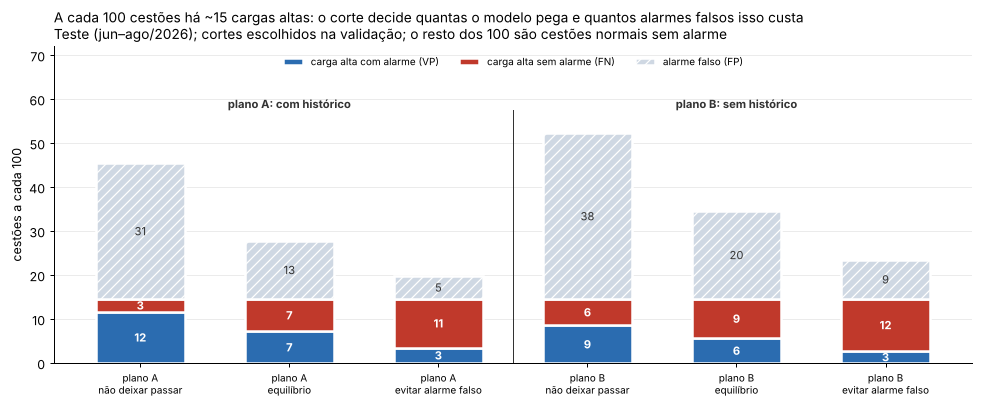

In [24]:
# Gráfico 06: o que acontece a cada 100 cestões no teste, por corte e plano
fig, ax = plt.subplots(figsize=(11, 4.6))
rotulos, vps, fns, fps = [], [], [], []
for (plano, corte), r in tab_teste.iterrows():
    rotulos.append(f"plano {plano[0]}\n{corte}")
    vps.append(r["VP/100"]); fns.append(r["FN/100"]); fps.append(r["FP/100"])
x = np.arange(len(rotulos))
ax.bar(x, vps, color=AZUL, width=0.6, edgecolor="white", linewidth=2, label="carga alta com alarme (VP)")
ax.bar(x, fns, bottom=vps, color=VERMELHO, width=0.6, edgecolor="white", linewidth=2, label="carga alta sem alarme (FN)")
ax.bar(x, fps, bottom=np.add(vps, fns), color="#cfd8e3", width=0.6, edgecolor="white", linewidth=2,
       hatch="///", label="alarme falso (FP)")
for xi, a, b, c in zip(x, vps, fns, fps):
    ax.annotate(f"{a:.0f}", (xi, a / 2), ha="center", va="center", fontsize=9, color="white", fontweight="bold")
    ax.annotate(f"{b:.0f}", (xi, a + b / 2), ha="center", va="center", fontsize=9, color="white", fontweight="bold")
    ax.annotate(f"{c:.0f}", (xi, a + b + c / 2), ha="center", va="center", fontsize=9, color="#333")
ax.axvline(2.5, color="#333", lw=0.8, ymax=0.8)
ax.annotate("plano A: com histórico", (1, 58), ha="center", fontsize=9, color="#333", fontweight="bold")
ax.annotate("plano B: sem histórico", (4, 58), ha="center", fontsize=9, color="#333", fontweight="bold")
ax.set_xticks(x, rotulos, fontsize=8)
ax.set_ylabel("cestões a cada 100")
ax.set_ylim(0, 72)
ax.legend(fontsize=8, frameon=False, loc="upper center", ncol=3)
ax.set_title(f"A cada 100 cestões há ~{100 * y_te.mean():.0f} cargas altas: o corte decide quantas o modelo pega "
             "e quantos alarmes falsos isso custa\n"
             "Teste (jun–ago/2026); cortes escolhidos na validação; o resto dos 100 são cestões normais sem alarme",
             loc="left", fontsize=11)
ax.grid(axis="x", visible=False)
salvar("06_a_cada_100_cestoes_no_teste")

## 12. E as métricas de regressão? (slides 24 a 29)

MAE e RMSE medem "quanto erramos" quando a resposta é um **número**. A pergunta da EVCOMX
("este cestão vai dar carga alta?") é sim ou não, então elas **não se aplicam** ao modelo.

O único número do problema é a **duração da parada**. Prever a duração seria regressão, mas ela
só existe depois que a carga alta acontece, então não serve para decidir antes de despejar o
cestão. Ela entrou aqui só para traduzir os erros em minutos (seções 1, 10 e 11).

O Brier score da seção 8 é o parente mais próximo do RMSE na classificação: é o erro quadrático
médio da **chance** prevista.

## 13. Conclusão: o desempenho é bom o suficiente para uso operacional? (Guia FE/FS §11.2)

A resposta depende de duas coisas que só a EVCOMX sabe: **quanto custa um alarme falso** (o `k`)
e **quantos alarmes o pátio aguenta**. A célula abaixo monta a conclusão com os números desta
rodada, para que ela continue certa se os dados mudarem (por exemplo, depois da pergunta 2 do
e-mail).

In [25]:
r = tab_teste.loc[("A (com histórico)", CURTO[CENARIOS[0]])]
eco_te = tab_custo_teste["economia_%"]
uso_vs_regra = tab_uso_regra["leitura"].to_dict()
fk = faixas_k.round(2)
print(f"""CONCLUSÃO (teste, jun–ago/2026)

1. Contra a operação de hoje (sem alarme): o modelo ajuda, mas o tamanho do ganho depende de k.
   - Corte '{CURTO[CENARIOS[0]]}': pega {100 * r['recall']:.0f}% das cargas altas e cobre ~{r['min. de parada cobertos /30 dias']:.0f} de
     ~{tab_parada.loc['teste', 'total_min_por_30_dias']:.0f} min de parada a cada 30 dias, com ~{r['alarmes/100']:.0f} alarmes a cada 100 cestões
     ({br(r['alarmes falsos por acerto'], 1)} alarmes falsos por acerto).
   - Economia no teste, com cortes vindos da validação: {', '.join(f'{eco_te[k]:.0f}% com k = {k}' for k in eco_te.index)}.
     Com k pequeno, o ganho é quase nulo.

2. Contra a regra simples do histórico ('carga alta nas últimas 5 corridas'):
   - modelo treinado só no treino: PR-AUC {tab_pareada_teste.loc[('Regra: mais taxa_ca_ult5 (só histórico)', 'PR-AUC'), 'leitura']}, recall com 20 alarmes por 100 {tab_pareada_teste.loc[('Regra: mais taxa_ca_ult5 (só histórico)', 'recall 20/100'), 'leitura']};
   - modelo para uso (treino + validação): PR-AUC {uso_vs_regra['PR-AUC']}, recall com 20 alarmes por 100 {uso_vs_regra['recall 20/100']}.
   Antes de dizer que a composição do cestão agrega à regra, é preciso entender maio/2026 e medir de novo.

3. A chance crua não deve ir para o pátio: ela é {br(razao.min(), 1)} a {br(razao.max(), 1)} vezes a taxa real.
   Usar faixas de risco com a taxa real de cada faixa (seção 8).

4. O corte depende de k (validação):
   - '{CURTO[CENARIOS[2]]}': k de {br(fk.loc[CURTO[CENARIOS[2]], 'min'])} a {br(fk.loc[CURTO[CENARIOS[2]], 'max'])};
   - '{CURTO[CENARIOS[1]]}': k de {br(fk.loc[CURTO[CENARIOS[1]], 'min'])} a {br(fk.loc[CURTO[CENARIOS[1]], 'max'])};
   - '{CURTO[CENARIOS[0]]}': k de {br(fk.loc[CURTO[CENARIOS[0]], 'min'])} em diante.
   Na operação, fixar o corte pelo volume de alarmes e recalcular o limiar a cada re-treino.""")

CONCLUSÃO (teste, jun–ago/2026)

1. Contra a operação de hoje (sem alarme): o modelo ajuda, mas o tamanho do ganho depende de k.
   - Corte 'não deixar passar': pega 80% das cargas altas e cobre ~155 de
     ~185 min de parada a cada 30 dias, com ~43 alarmes a cada 100 cestões
     (2,6 alarmes falsos por acerto).
   - Economia no teste, com cortes vindos da validação: 1% com k = 2, 12% com k = 3, 33% com k = 5, 35% com k = 8, 28% com k = 10.
     Com k pequeno, o ganho é quase nulo.

2. Contra a regra simples do histórico ('carga alta nas últimas 5 corridas'):
   - modelo treinado só no treino: PR-AUC empate, recall com 20 alarmes por 100 desvantagem real;
   - modelo para uso (treino + validação): PR-AUC empate, recall com 20 alarmes por 100 empate.
   Antes de dizer que a composição do cestão agrega à regra, é preciso entender maio/2026 e medir de novo.

3. A chance crua não deve ir para o pátio: ela é 2,1 a 2,4 vezes a taxa real.
   Usar faixas de risco com a taxa real de cada faix

## 14. Arquivos gerados

In [26]:
tab_cv_csv = tab_cv.copy()
tab_cv_csv.columns = [f"{m}_{s}" for m, s in tab_cv_csv.columns]
tab_cv_csv.to_csv(PASTA_SAIDA / "metricas_cv_temporal.csv")
tab_val.to_csv(PASTA_SAIDA / "metricas_validacao.csv")
tab_baseline.to_csv(PASTA_SAIDA / "baselines_validacao.csv")
tab_pareada.to_csv(PASTA_SAIDA / "comparacao_pareada_validacao.csv")
tab_pareada_teste.to_csv(PASTA_SAIDA / "comparacao_pareada_teste.csv")
pd.concat({"metricas": tab_uso}).to_csv(PASTA_SAIDA / "modelo_para_uso_no_teste.csv")
tab_uso_regra.to_csv(PASTA_SAIDA / "modelo_para_uso_contra_regra.csv")
tab_uso_limiar.to_csv(PASTA_SAIDA / "modelo_para_uso_limiares.csv")
tab_custo.to_csv(PASTA_SAIDA / "custo_conforme_k_validacao.csv", index=False)
faixas.to_csv(PASTA_SAIDA / "faixas_de_risco.csv")
tab_mes.assign(**{"período": tab_mes["período"].str.replace("\n", " ")}).to_csv(PASTA_SAIDA / "metricas_por_periodo.csv", index=False)
tab_minutos.to_csv(PASTA_SAIDA / "recall_em_minutos.csv")
tab_teste.to_csv(PASTA_SAIDA / "teste_traduzido.csv")
tab_custo_teste.to_csv(PASTA_SAIDA / "custo_no_teste.csv")
print("Arquivos salvos em", PASTA_SAIDA.relative_to(RAIZ))

Arquivos salvos em analise_modelos
